Setup

In [8]:
#cell 1
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# 1. Reproducibility 
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device("cpu")

# 2. Project Constants & Schema
DATA_PATH = Path("wine2.csv")
CHEMICALS = [
    "fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar",
    "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density",
    "pH", "sulphates", "alcohol",
]
FEATURES = CHEMICALS + ["wine_type_red"]
CLASSES = ["Low", "Medium", "High"]
CLASS_TO_IDX = {label: idx for idx, label in enumerate(CLASSES)}
IDX_TO_CLASS = {idx: label for idx, label in enumerate(CLASSES)}

# 3. Plotting Defaults
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

Data Loading

In [9]:
#cell 2
# 1. Load dataset (checks wine2.csv first, then wine2_2.csv)
csv_file = DATA_PATH if DATA_PATH.exists() else Path("wine2_2.csv")
raw_df = pd.read_csv(csv_file)

required_cols = CHEMICALS + ["wine_type", "quality_class"]
assert set(required_cols).issubset(raw_df.columns), f"Missing columns: {set(required_cols) - set(raw_df.columns)}"
assert not raw_df[required_cols].isna().any().any(), "Dataset contains missing values!"

# 2. Remove exact duplicate feature+target rows to prevent data leakage across splits
df = raw_df[required_cols].drop_duplicates().reset_index(drop=True)
print(f"Loaded '{csv_file.name}': {len(raw_df):,} raw rows -> {len(df):,} unique rows ({len(raw_df) - len(df)} duplicates removed).")

# 3. Build feature matrix X (11 chemicals + 1 binary wine type) and integer target y (Low=0, Medium=1, High=2)
X = df[CHEMICALS].copy()
X["wine_type_red"] = (df["wine_type"] == "red").astype(float)
y = df["quality_class"].map(CLASS_TO_IDX).to_numpy(dtype=np.int64)

assert list(X.columns) == FEATURES
assert (y >= 0).all() and (y < len(CLASSES)).all()

# 4. Stratified 85/15 Development vs. Locked Holdout Test Split
# (85/15 gives ~800 test rows, ensuring enough 'Low' quality wines in test for reliable F1/ROC metrics)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

# Reset indices cleanly so K-Fold indexing is simple and bug-free
X_dev = X_dev.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

# 5. Summary Audit Table
summary_df = pd.DataFrame({
    "Total Unique": pd.Series(y).value_counts().reindex(range(3)),
    "Dev Set (85%)": pd.Series(y_dev).value_counts().reindex(range(3)),
    "Locked Test (15%)": pd.Series(y_test).value_counts().reindex(range(3)),
})
summary_df.index = CLASSES
summary_df["Share (%)"] = (summary_df["Total Unique"] / len(df) * 100).round(1)
print("\nClass distribution across splits:")
display(summary_df)

Loaded 'wine2.csv': 5,320 raw rows -> 5,320 unique rows (0 duplicates removed).

Class distribution across splits:


,Total Unique,Dev Set (85%),Locked Test (15%),Share (%)
Low,236,200,36,4.4
Medium,4075,3464,611,76.6
High,1009,858,151,19.0


EDA

Dataset shape after deduplication: 5,320 rows × 13 columns


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,wine_type,quality_class
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,red,Medium
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,red,Medium
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,red,Medium
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,red,Medium
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,red,Medium


C:\Users\micoc\AppData\Local\Temp\ipykernel_10656\1676706352.py:54: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\micoc\OneDrive\Documents\GitHub\ads2026\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


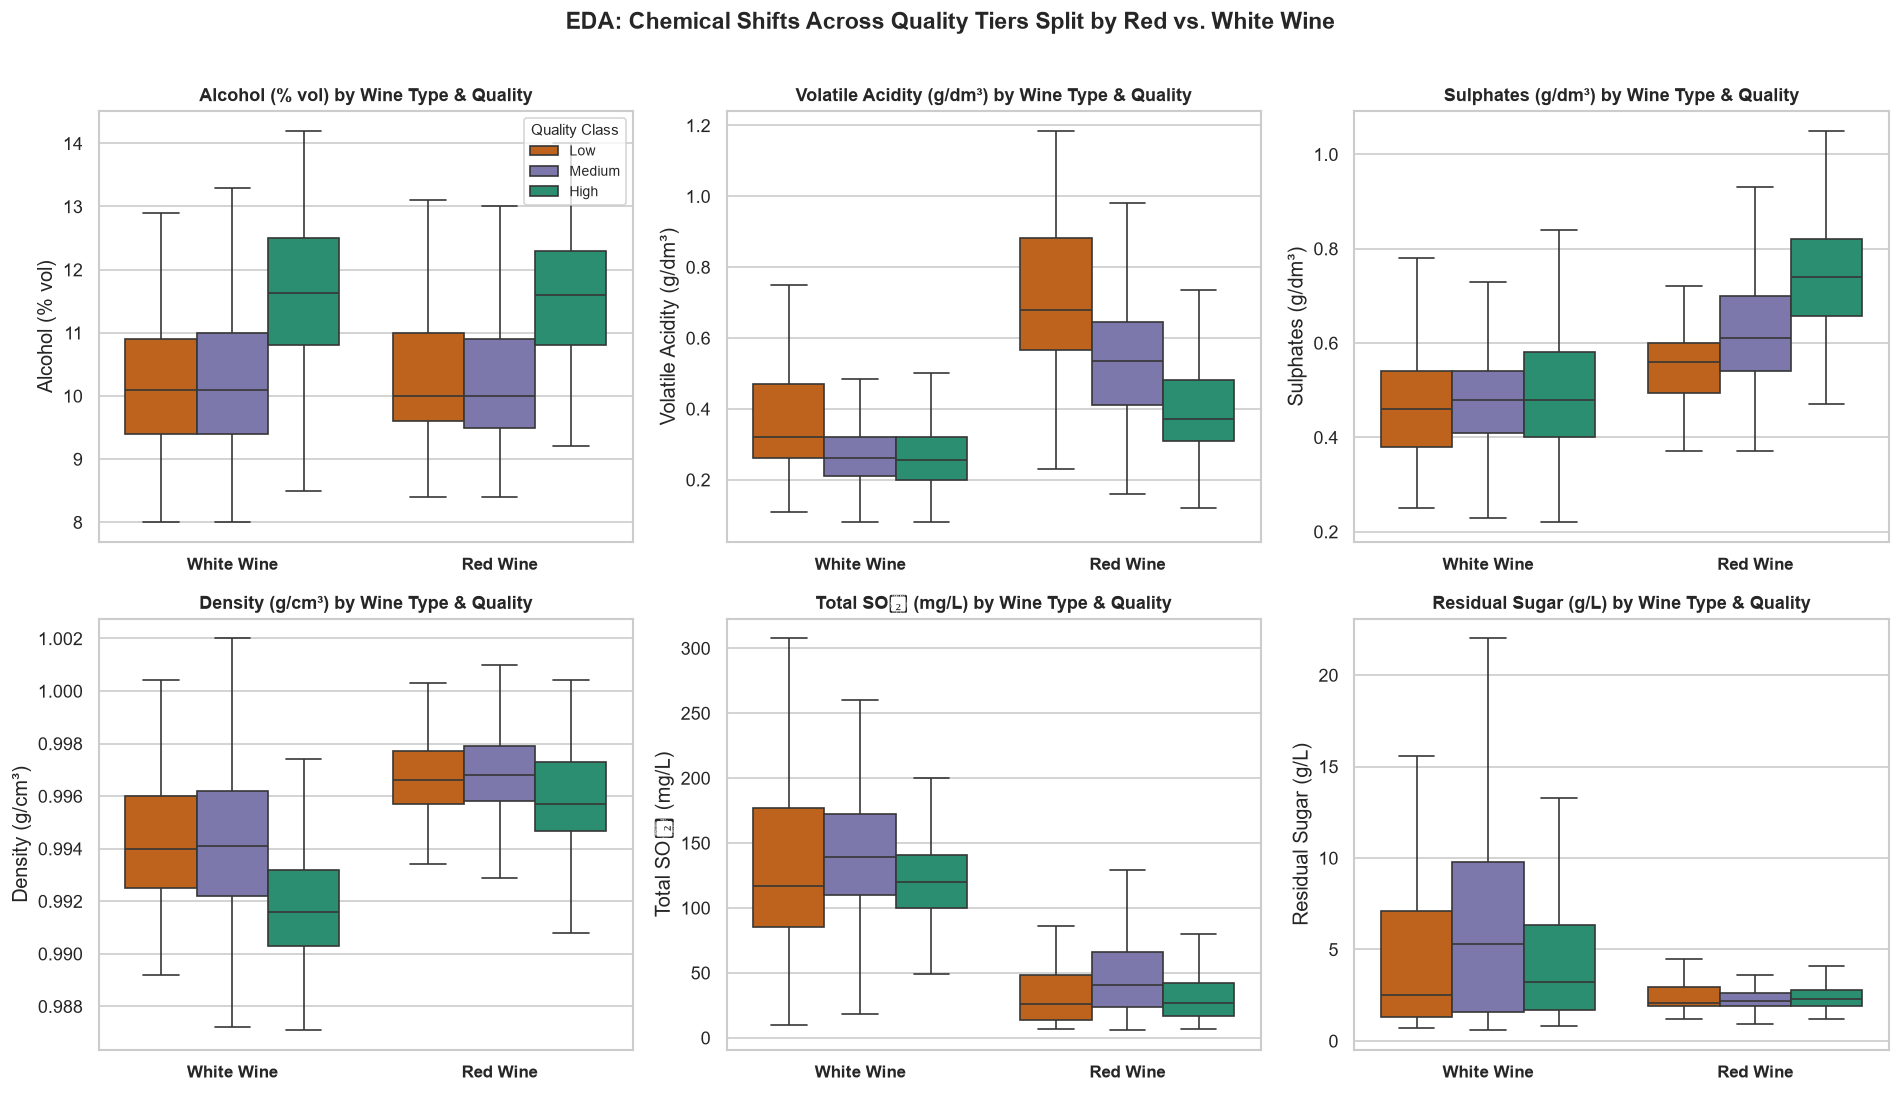

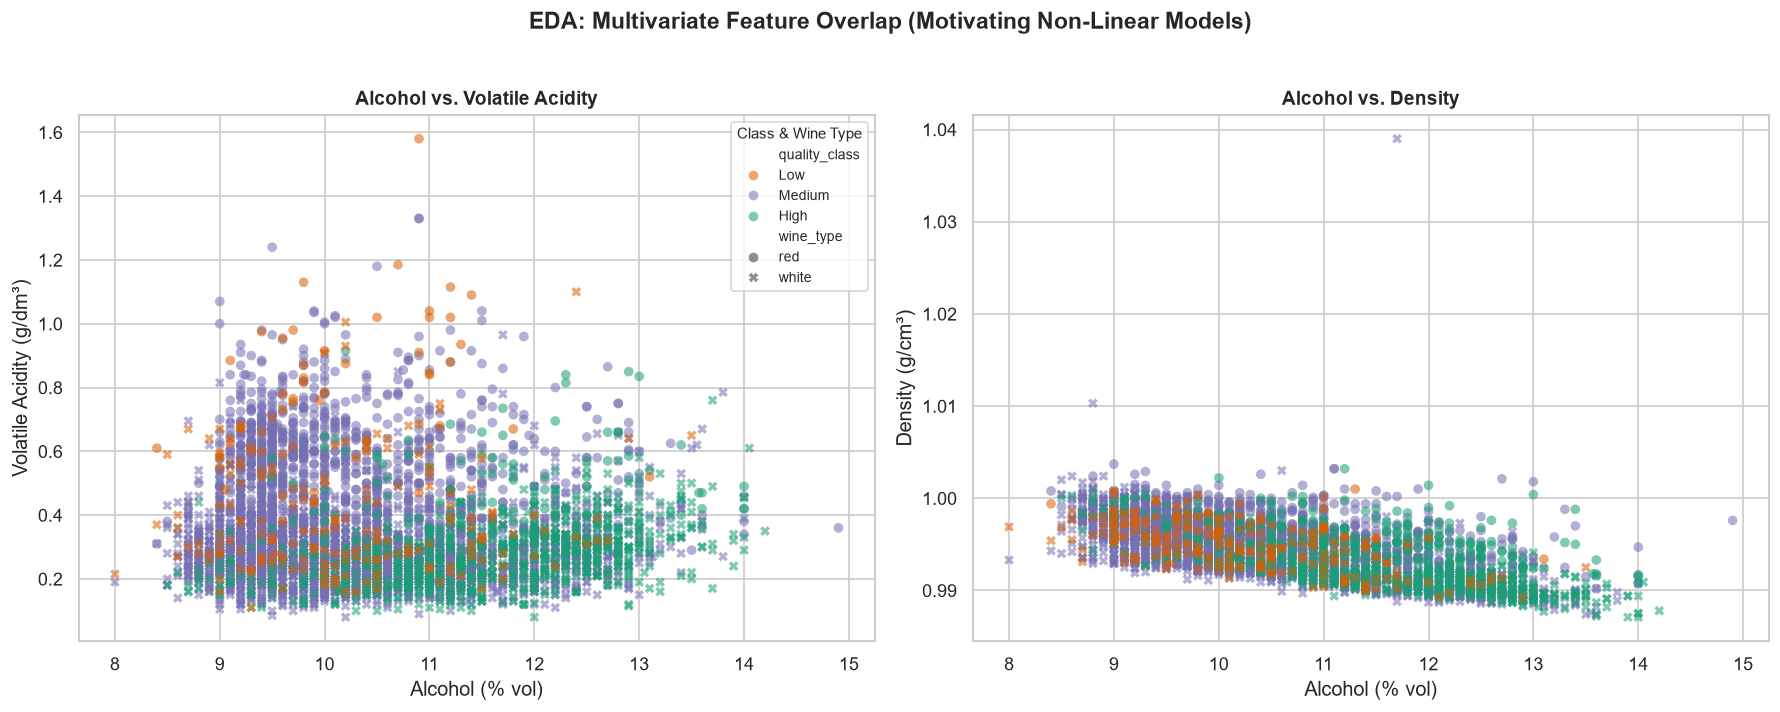

In [16]:
#cell 3

PALETTE = {"Low": "#d95f02", "Medium": "#7570b3", "High": "#1b9e77"}

# 1. Dataset Preview (first 5 unique rows of wine2.csv)
print(f"Dataset shape after deduplication: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

# ==============================================================================
# 2. BOXPLOTS: CHEMICAL PROFILES BY QUALITY TIER & WINE TYPE (RED VS. WHITE)
# (Complements correlation heatmap by showing how red & white baselines differ)
# ==============================================================================
box_features = [
    ("alcohol", "Alcohol (% vol)"),
    ("volatile_acidity", "Volatile Acidity (g/dm³)"),
    ("sulphates", "Sulphates (g/dm³)"),
    ("density", "Density (g/cm³)"),
    ("total_sulfur_dioxide", "Total SO₂ (mg/L)"),
    ("residual_sugar", "Residual Sugar (g/L)"),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, (col, label) in enumerate(box_features):
    ax = axes[idx]
    sns.boxplot(
        data=df,
        x="wine_type",
        y=col,
        order=["white", "red"],
        hue="quality_class",
        hue_order=CLASSES,
        palette=PALETTE,
        showfliers=False,  # Hides extreme outliers so medians & IQRs read cleanly on slides
        ax=ax,
    )
    ax.set_title(f"{label} by Wine Type & Quality", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["White Wine", "Red Wine"], fontsize=10, fontweight="bold")
    ax.set_ylabel(label)
    if idx == 0:
        ax.legend(title="Quality Class", loc="upper right", fontsize=8.5, title_fontsize=9)
    else:
        ax.get_legend().remove()

plt.suptitle(
    "EDA: Chemical Shifts Across Quality Tiers Split by Red vs. White Wine",
    fontsize=14,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. BIVARIATE SCATTERPLOTS: MULTIVARIATE FEATURE INTERACTIONS & CLASS OVERLAP
# (Visually motivates non-linear classifiers before introducing KNN / RF / MLP)
# ==============================================================================
plot_df = pd.concat([
    df[df["quality_class"] == "Medium"],
    df[df["quality_class"] == "High"],
    df[df["quality_class"] == "Low"],
], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

scatter_specs = [
    ("volatile_acidity", "Volatile Acidity (g/dm³)", "Alcohol vs. Volatile Acidity"),
    ("density", "Density (g/cm³)", "Alcohol vs. Density"),
]

for idx, (y_col, y_lbl, title) in enumerate(scatter_specs):
    ax = axes[idx]
    sns.scatterplot(
        data=plot_df,
        x="alcohol",
        y=y_col,
        hue="quality_class",
        hue_order=CLASSES,
        palette=PALETTE,
        style="wine_type",
        alpha=0.55,
        s=34,
        edgecolor="none",
        ax=ax,
        legend=(idx == 0),
    )
    ax.set_title(title, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Alcohol (% vol)")
    ax.set_ylabel(y_lbl)

axes[0].legend(title="Class & Wine Type", loc="upper right", fontsize=8.5, title_fontsize=9)
plt.suptitle(
    "EDA: Multivariate Feature Overlap (Motivating Non-Linear Models)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

Shared Metrics + Neural Network Architecture

In [ ]:
#cell 4

def evaluate_predictions(y_true, y_proba):
    """Compute identical classification metrics across all model families."""
    y_pred = np.argmax(y_proba, axis=1)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "macro_roc_auc": float(roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro")),
    }


class WineMLP(nn.Module):
    """Regularized Multilayer Perceptron for 3-class wine quality classification."""
    def __init__(self, input_dim, hidden_dims=(64, 32), dropout=0.25):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.ReLU(),
                nn.Dropout(dropout),
            ])
            prev_dim = h_dim
        layers.append(nn.Linear(prev_dim, len(CLASSES)))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def train_and_predict_nn(
    X_tr, y_tr, X_eval,
    hidden_dims=(64, 32),
    max_epochs=150,
    patience=25,
    lr=1e-3,
    weight_decay=1e-2,
    seed=SEED,
):
    """Train MLP with class-weighted cross-entropy and inner early stopping."""
    torch.manual_seed(seed)
    np.random.seed(seed)

    # 1. Carve out a 15% stratified inner validation split for early stopping
    X_inner_tr, X_inner_val, y_inner_tr, y_inner_val = train_test_split(
        X_tr, y_tr, test_size=0.15, random_state=seed, stratify=y_tr
    )

    # 2. Compute inverse-frequency class weights on inner training rows only
    weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(CLASSES)), y=y_inner_tr)
    class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # 3. Build model, optimizer, and DataLoader
    model = WineMLP(input_dim=X_tr.shape[1], hidden_dims=hidden_dims, dropout=0.25).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_inner_tr, dtype=torch.float32),
            torch.tensor(y_inner_tr, dtype=torch.long),
        ),
        batch_size=64,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    X_val_t = torch.tensor(X_inner_val, dtype=torch.float32, device=DEVICE)
    X_eval_t = torch.tensor(X_eval, dtype=torch.float32, device=DEVICE)

    best_val_f1 = -1.0
    best_epoch = 1
    best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    # 4. Training loop with early stopping on inner validation Macro F1
    for epoch in range(1, max_epochs + 1):
        model.train()
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_proba = torch.softmax(model(X_val_t), dim=1).cpu().numpy()
            val_f1 = f1_score(y_inner_val, np.argmax(val_proba, axis=1), average="macro", zero_division=0)

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = epoch
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= patience:
            break

    # 5. Restore best checkpoint and predict probabilities on X_eval
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        eval_proba = torch.softmax(model(X_eval_t), dim=1).cpu().numpy()

    return eval_proba, best_epoch


Cross Validation

In [ ]:
#cell 5A
N_FOLDS = 10
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# Define candidate models to compare on identical folds
def get_sklearn_candidates():
    return {
        "KNN (k=3, manhattan)": KNeighborsClassifier(n_neighbors=3, weights="distance", metric="manhattan"),
        "KNN (k=7, manhattan)": KNeighborsClassifier(n_neighbors=7, weights="distance", metric="manhattan"),
        "KNN (k=15, manhattan)": KNeighborsClassifier(n_neighbors=15, weights="distance", metric="manhattan"),
        "Random Forest (depth=12, balanced)": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_leaf=2,
            class_weight="balanced_subsample", random_state=SEED, n_jobs=-1
        ),
        "Random Forest (unpruned, balanced)": RandomForestClassifier(
            n_estimators=300, max_depth=None, min_samples_leaf=1,
            class_weight="balanced_subsample", random_state=SEED, n_jobs=-1
        ),
    }

NN_CANDIDATES = {
    "Neural Net (32-16, weighted)": (32, 16),
    "Neural Net (64-32, weighted)": (64, 32),
}

cv_records = []
oof_predictions = {}  # Store out-of-fold probability arrays for ROC/confusion plots

all_model_names = list(get_sklearn_candidates().keys()) + list(NN_CANDIDATES.keys())
for name in all_model_names:
    oof_predictions[name] = np.zeros((len(X_dev), len(CLASSES)), dtype=float)

print(f"Starting {N_FOLDS}-Fold Stratified Cross-Validation on {len(X_dev):,} development rows...\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
    # 1. Fit scaler ONLY on training fold to prevent data leakage
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_dev.iloc[train_idx])
    X_va = scaler.transform(X_dev.iloc[val_idx])
    y_tr, y_va = y_dev[train_idx], y_dev[val_idx]

    # 2. Train & evaluate KNN and Random Forest candidates
    for name, clf in get_sklearn_candidates().items():
        clf.fit(X_tr, y_tr)
        # Ensure columns strictly match CLASSES order [0, 1, 2]
        col_order = [list(clf.classes_).index(i) for i in range(len(CLASSES))]
        proba = clf.predict_proba(X_va)[:, col_order]
        oof_predictions[name][val_idx] = proba

        scores = evaluate_predictions(y_va, proba)
        cv_records.append({"model": name, "fold": fold, **scores})

    # 3. Train & evaluate Neural Network candidates
    for name, hidden_dims in NN_CANDIDATES.items():
        proba, best_ep = train_and_predict_nn(
            X_tr, y_tr, X_va,
            hidden_dims=hidden_dims,
            seed=SEED + fold
        )
        oof_predictions[name][val_idx] = proba

        scores = evaluate_predictions(y_va, proba)
        cv_records.append({"model": name, "fold": fold, "best_epoch": best_ep, **scores})

    print(f"Fold {fold}/{N_FOLDS} complete.")

cv_df = pd.DataFrame(cv_records)

# Summarize mean and standard deviation across folds, ranked by Macro F1
summary_cv = (
    cv_df.groupby("model")[["macro_f1", "accuracy", "macro_roc_auc", "weighted_f1"]]
    .agg(["mean", "std"])
    .sort_values(("macro_f1", "mean"), ascending=False)
)

print("\n=== 10-FOLD CROSS-VALIDATION LEADERBOARD (Ranked by Macro F1) ===")
display(summary_cv.round(4))

best_model_name = summary_cv.index[0]

Starting 10-Fold Stratified Cross-Validation on 4,522 development rows...

Fold 1/10 complete.
Fold 2/10 complete.
Fold 3/10 complete.
Fold 4/10 complete.
Fold 5/10 complete.
Fold 6/10 complete.
Fold 7/10 complete.
Fold 8/10 complete.
Fold 9/10 complete.
Fold 10/10 complete.

=== 10-FOLD CROSS-VALIDATION LEADERBOARD (Ranked by Macro F1) ===


macro_f1         accuracy          \
                                       mean     std     mean     std   
model                                                                  
KNN (k=3, manhattan)                 0.5314  0.0418   0.7795  0.0194   
Random Forest (depth=12, balanced)   0.5055  0.0456   0.7751  0.0236   
Neural Net (64-32, weighted)         0.5025  0.0257   0.6123  0.0330   
Neural Net (32-16, weighted)         0.5023  0.0268   0.6187  0.0440   
KNN (k=7, manhattan)                 0.4987  0.0478   0.7915  0.0209   
KNN (k=15, manhattan)                0.4733  0.0336   0.7970  0.0135   
Random Forest (unpruned, balanced)   0.4562  0.0300   0.7988  0.0102   

                                   macro_roc_auc         weighted_f1          
                                            mean     std        mean     std  
model                                                                         
KNN (k=3, manhattan)                      0.7367  0.0434      0.7682  0.0209  
Random Forest (depth=12, balanced)        0.8297  0.0254      0.7650  0.0225  
Neural Net (64-32, weighted)              0.8058  0.0233      0.6493  0.0318  
Neural Net (32-16, weighted)              0.8013  0.0225      0.6535  0.0377  
KNN (k=7, manhattan)                      0.7841  0.0429      0.7686  0.0229  
KNN (k=15, manhattan)                     0.8031  0.0408      0.7666  0.0151  
Random Forest (unpruned, balanced)        0.8365  0.0274      0.7600  0.0129


Winning architecture selected for final training: KNN (k=3, manhattan)


In [ ]:
#CELL 5B
from itertools import product

# 1. Update Neural Network helper so dropout is tunable alongside lr and architecture
def train_and_predict_nn_tuned(
    X_tr, y_tr, X_eval,
    hidden_dims=(64, 32),
    dropout=0.25,
    lr=1e-3,
    weight_decay=1e-2,
    max_epochs=150,
    patience=25,
    seed=SEED,
):
    torch.manual_seed(seed)
    np.random.seed(seed)

    X_inner_tr, X_inner_val, y_inner_tr, y_inner_val = train_test_split(
        X_tr, y_tr, test_size=0.15, random_state=seed, stratify=y_tr
    )

    weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(CLASSES)), y=y_inner_tr)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE))

    model = WineMLP(input_dim=X_tr.shape[1], hidden_dims=hidden_dims, dropout=dropout).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_inner_tr, dtype=torch.float32),
            torch.tensor(y_inner_tr, dtype=torch.long),
        ),
        batch_size=64,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    X_val_t = torch.tensor(X_inner_val, dtype=torch.float32, device=DEVICE)
    X_eval_t = torch.tensor(X_eval, dtype=torch.float32, device=DEVICE)

    best_val_f1 = -1.0
    best_epoch = 1
    best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    for epoch in range(1, max_epochs + 1):
        model.train()
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_proba = torch.softmax(model(X_val_t), dim=1).cpu().numpy()
            val_f1 = f1_score(y_inner_val, np.argmax(val_proba, axis=1), average="macro", zero_division=0)

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = epoch
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        eval_proba = torch.softmax(model(X_eval_t), dim=1).cpu().numpy()

    return eval_proba, best_epoch


# 2. Define Hyperparameter Grids
knn_grid = [
    {"k": k, "metric": m, "weights": w}
    for k, m, w in product([3, 7, 15, 25], ["manhattan", "euclidean"], ["distance", "uniform"])
]

rf_grid = [
    {"n_estimators": n_trees, "max_depth": depth, "min_samples_leaf": leaf}
    for n_trees, depth, leaf in product([100, 300, 500], [10, 16, None], [1, 3])
]

nn_grid = [
    {"hidden_dims": h, "lr": lr, "dropout": drop}
    for h, lr, drop in product([(32, 16), (64, 32)], [1e-3, 3e-4], [0.15, 0.35])
]

print(f"Tuning {len(knn_grid)} KNN configs, {len(rf_grid)} Random Forest configs, and {len(nn_grid)} Neural Net configs across {N_FOLDS} folds...")

# 3. Pre-scale folds once so every configuration sees identical data
scaled_folds = []
for fold, (train_idx, val_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_dev.iloc[train_idx])
    X_va = scaler.transform(X_dev.iloc[val_idx])
    scaled_folds.append((fold, train_idx, val_idx, X_tr, X_va, y_dev[train_idx], y_dev[val_idx]))

tuning_records = []
tuned_oof = {}
y_high_dev = (y_dev == CLASS_TO_IDX["High"]).astype(int)

def record_oof_result(family, label, params, oof_proba):
    tuned_oof[label] = oof_proba
    overall = evaluate_predictions(y_dev, oof_proba)
    p_high = oof_proba[:, CLASS_TO_IDX["High"]]
    pred_high = (np.argmax(oof_proba, axis=1) == CLASS_TO_IDX["High"]).astype(int)
    tuning_records.append({
        "family": family,
        "config": label,
        "params": params,
        "high_roc_auc": roc_auc_score(y_high_dev, p_high),
        "high_f1": f1_score(y_high_dev, pred_high, zero_division=0),
        "macro_f1": overall["macro_f1"],
        "macro_roc_auc": overall["macro_roc_auc"],
        "accuracy": overall["accuracy"],
    })

# 4. Run KNN Grid
for cfg in knn_grid:
    label = f"KNN(k={cfg['k']}, {cfg['metric'][:4]}, {cfg['weights'][:4]})"
    oof_p = np.zeros((len(X_dev), len(CLASSES)))
    for fold, tr_idx, va_idx, X_tr, X_va, y_tr, y_va in scaled_folds:
        clf = KNeighborsClassifier(n_neighbors=cfg["k"], metric=cfg["metric"], weights=cfg["weights"], n_jobs=-1)
        clf.fit(X_tr, y_tr)
        col_order = [list(clf.classes_).index(i) for i in range(len(CLASSES))]
        oof_p[va_idx] = clf.predict_proba(X_va)[:, col_order]
    record_oof_result("KNN", label, cfg, oof_p)

# 5. Run Random Forest Grid
for cfg in rf_grid:
    label = f"RF(trees={cfg['n_estimators']}, depth={cfg['max_depth']}, leaf={cfg['min_samples_leaf']})"
    oof_p = np.zeros((len(X_dev), len(CLASSES)))
    for fold, tr_idx, va_idx, X_tr, X_va, y_tr, y_va in scaled_folds:
        clf = RandomForestClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            min_samples_leaf=cfg["min_samples_leaf"],
            class_weight="balanced_subsample",
            random_state=SEED,
            n_jobs=-1,
        )
        clf.fit(X_tr, y_tr)
        col_order = [list(clf.classes_).index(i) for i in range(len(CLASSES))]
        oof_p[va_idx] = clf.predict_proba(X_va)[:, col_order]
    record_oof_result("Random Forest", label, cfg, oof_p)

# 6. Run Neural Network Grid
for idx, cfg in enumerate(nn_grid, start=1):
    label = f"MLP({cfg['hidden_dims']}, lr={cfg['lr']}, drop={cfg['dropout']})"
    oof_p = np.zeros((len(X_dev), len(CLASSES)))
    for fold, tr_idx, va_idx, X_tr, X_va, y_tr, y_va in scaled_folds:
        proba, _ = train_and_predict_nn_tuned(
            X_tr, y_tr, X_va,
            hidden_dims=cfg["hidden_dims"],
            lr=cfg["lr"],
            dropout=cfg["dropout"],
            seed=SEED + fold,
        )
        oof_p[va_idx] = proba
    record_oof_result("Neural Net", label, cfg, oof_p)
    print(f"  Completed Neural Net config {idx}/{len(nn_grid)}: {label}")

tuning_df = pd.DataFrame(tuning_records)

# 7. Show Top 3 Tuned Configurations per Model Family (Ranked by High-Class ROC AUC)
print("\n=== TOP 3 CONFIGURATIONS PER MODEL FAMILY (Ranked by High-Quality ROC AUC) ===")
top_per_family_df = (
    tuning_df.sort_values("high_roc_auc", ascending=False)
    .groupby("family", as_index=False)
    .head(3)
    .sort_values(["family", "high_roc_auc"], ascending=[True, False])
)
display(top_per_family_df[["family", "config", "high_roc_auc", "high_f1", "macro_f1", "macro_roc_auc", "accuracy"]].round(4))

# Identify best overall config per family for downstream plotting / final test
best_configs = (
    tuning_df.sort_values("high_roc_auc", ascending=False)
    .groupby("family", as_index=False)
    .first()
    .set_index("family")
)
print("\nBest configuration per architecture:")
display(best_configs[["config", "high_roc_auc", "high_f1", "macro_f1", "accuracy"]].round(4))

Tuning 16 KNN configs, 18 Random Forest configs, and 8 Neural Net configs across 10 folds...
  Completed Neural Net config 1/8: MLP((32, 16), lr=0.001, drop=0.15)
  Completed Neural Net config 2/8: MLP((32, 16), lr=0.001, drop=0.35)
  Completed Neural Net config 3/8: MLP((32, 16), lr=0.0003, drop=0.15)
  Completed Neural Net config 4/8: MLP((32, 16), lr=0.0003, drop=0.35)
  Completed Neural Net config 5/8: MLP((64, 32), lr=0.001, drop=0.15)
  Completed Neural Net config 6/8: MLP((64, 32), lr=0.001, drop=0.35)
  Completed Neural Net config 7/8: MLP((64, 32), lr=0.0003, drop=0.15)
  Completed Neural Net config 8/8: MLP((64, 32), lr=0.0003, drop=0.35)

=== TOP 3 CONFIGURATIONS PER MODEL FAMILY (Ranked by High-Quality ROC AUC) ===


,family,config,high_roc_auc,high_f1,macro_f1,macro_roc_auc,accuracy
8,KNN,"KNN(k=15, manh, dist)",0.8499,0.4884,0.4743,0.8030,0.7970
12,KNN,"KNN(k=25, manh, dist)",0.8485,0.4666,0.4612,0.8034,0.7968
14,KNN,"KNN(k=25, eucl, dist)",0.8463,0.4579,0.4449,0.8034,0.7954
38,Neural Net,"MLP((64, 32), lr=0.001, drop=0.15)",0.8428,0.5481,0.5038,0.8045,0.6194
40,Neural Net,"MLP((64, 32), lr=0.0003, drop=0.15)",0.8386,0.5507,0.5056,0.8026,0.6205
39,Neural Net,"MLP((64, 32), lr=0.001, drop=0.35)",0.8383,0.5443,0.4979,0.8023,0.6026
32,Random Forest,"RF(trees=500, depth=None, leaf=1)",0.8626,0.4520,0.4600,0.8373,0.7996
26,Random Forest,"RF(trees=300, depth=None, leaf=1)",0.8621,0.4455,0.4576,0.8363,0.7988
33,Random Forest,"RF(trees=500, depth=None, leaf=3)",0.8600,0.5437,0.5238,0.8349,0.7915



Best configuration per architecture:


,config,high_roc_auc,high_f1,macro_f1,accuracy
family,,,,,
KNN,"KNN(k=15, manh, dist)",0.8499,0.4884,0.4743,0.7970
Neural Net,"MLP((64, 32), lr=0.001, drop=0.15)",0.8428,0.5481,0.5038,0.6194
Random Forest,"RF(trees=500, depth=None, leaf=1)",0.8626,0.4520,0.4600,0.7996


Cross validation diagnostic charts

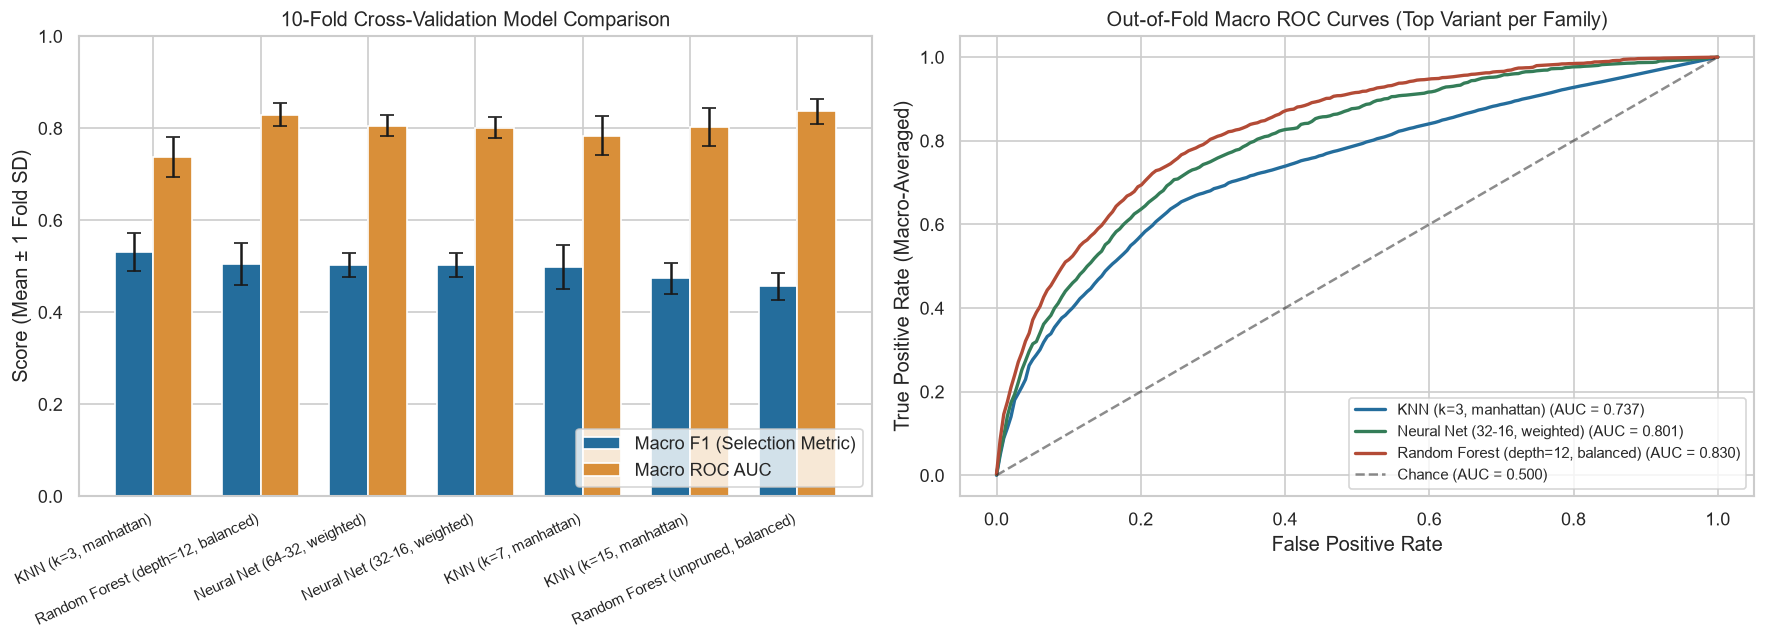

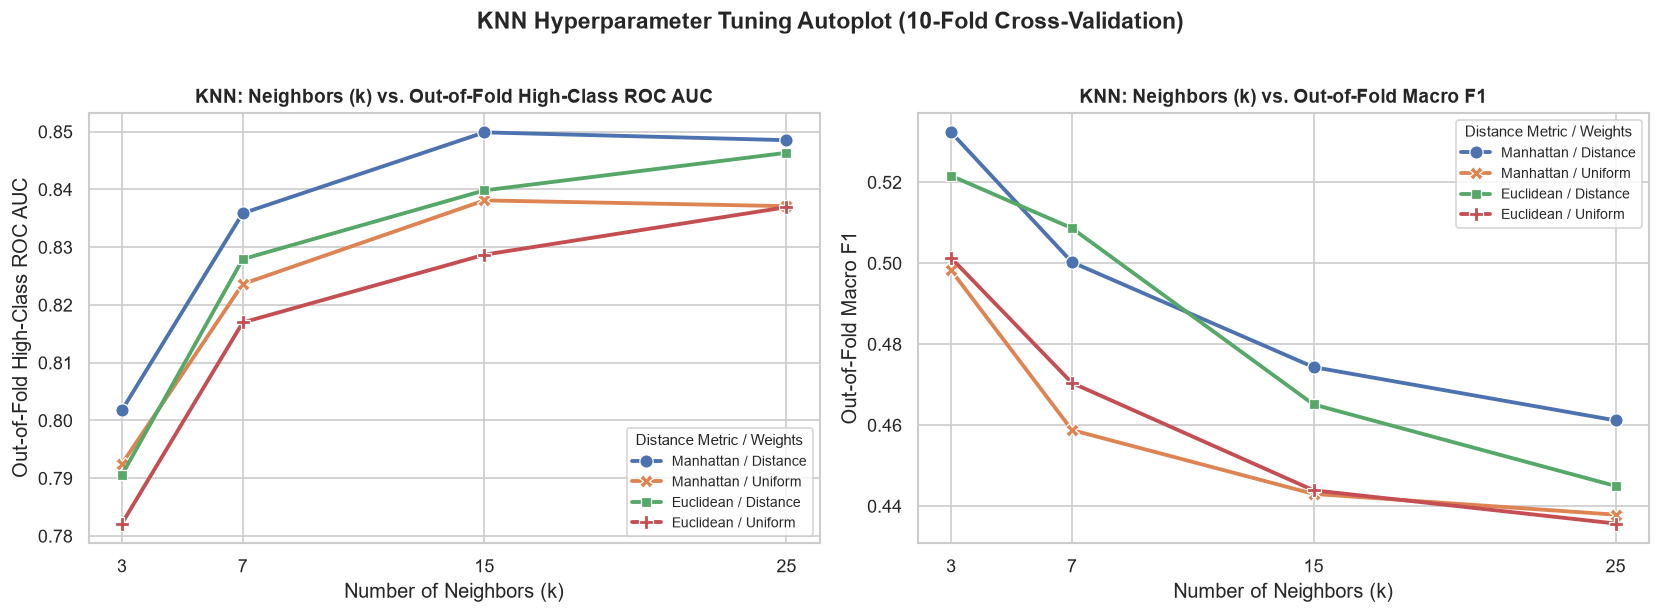

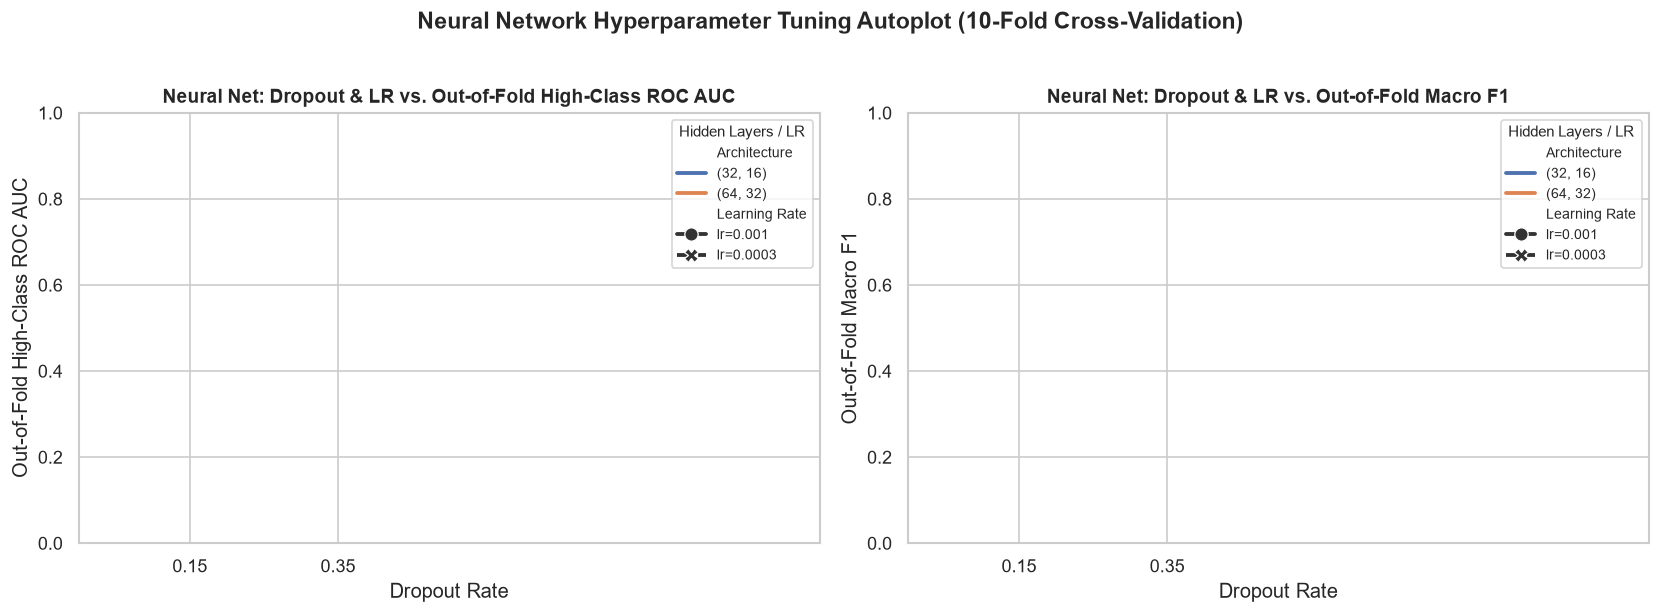

C:\Users\micoc\AppData\Local\Temp\ipykernel_10656\247638043.py:158: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  rf_plot["Max Depth"] = rf_plot["max_depth"].fillna("None (Unpruned)").astype(str)


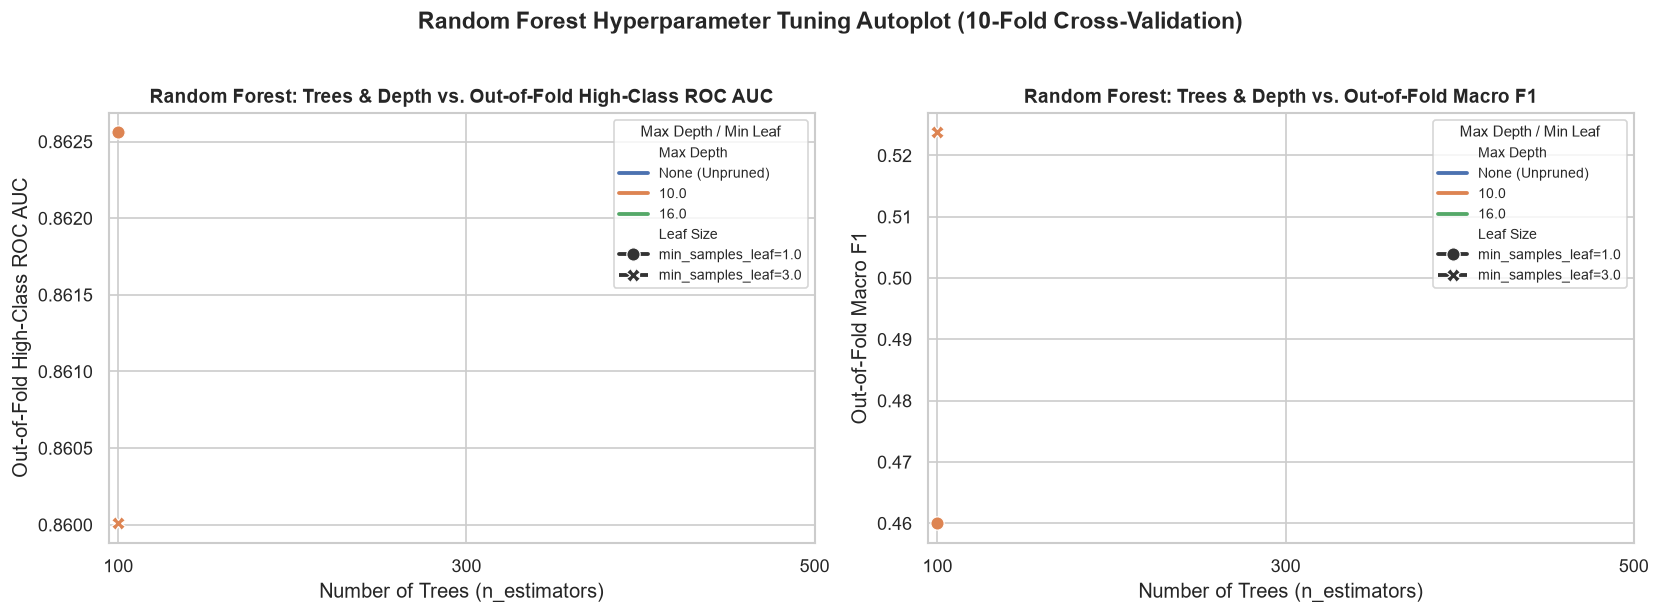

In [17]:
#cell 6
# Select the top variant from each model family for clean visual comparison
top_per_family = [
    "KNN (k=3, manhattan)",
    "Neural Net (32-16, weighted)",
    "Random Forest (depth=12, balanced)",
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Left Plot: Mean Macro F1 vs. Macro ROC AUC across all 7 candidates
plot_df = summary_cv.reset_index()
x = np.arange(len(plot_df))
width = 0.36

b1 = axes[0].bar(
    x - width / 2, plot_df[("macro_f1", "mean")], width,
    yerr=plot_df[("macro_f1", "std")], capsize=4, label="Macro F1 (Selection Metric)", color="#246d9c"
)
b2 = axes[0].bar(
    x + width / 2, plot_df[("macro_roc_auc", "mean")], width,
    yerr=plot_df[("macro_roc_auc", "std")], capsize=4, label="Macro ROC AUC", color="#d98f39"
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(plot_df["model"], rotation=25, ha="right", fontsize=9)
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel("Score (Mean ± 1 Fold SD)")
axes[0].set_title("10-Fold Cross-Validation Model Comparison")
axes[0].legend(loc="lower right")

# 2. Right Plot: Out-of-Fold Macro ROC Curves (Top Model per Family)
colors = ["#246d9c", "#347d58", "#b34b36"]
for name, color in zip(top_per_family, colors):
    proba = oof_predictions[name]
    # Compute macro-averaged one-vs-rest ROC curve
    fpr_grid = np.linspace(0, 1, 200)
    mean_tpr = np.zeros_like(fpr_grid)
    for class_idx in range(len(CLASSES)):
        fpr, tpr, _ = roc_curve(y_dev == class_idx, proba[:, class_idx])
        mean_tpr += np.interp(fpr_grid, fpr, tpr)
    mean_tpr /= len(CLASSES)
    auc_val = summary_cv.loc[name, ("macro_roc_auc", "mean")]
    axes[1].plot(fpr_grid, mean_tpr, lw=2, color=color, label=f"{name} (AUC = {auc_val:.3f})")

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance (AUC = 0.500)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Macro-Averaged)")
axes[1].set_title("Out-of-Fold Macro ROC Curves (Top Variant per Family)")
axes[1].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()


# ==============================================================================
# 1. INDIVIDUAL KNN TUNING AUTOPLOT
# ==============================================================================
knn_df = tuning_df[tuning_df["family"] == "KNN"].copy()
knn_params = pd.json_normalize(knn_df["params"])
knn_plot = pd.concat(
    [knn_df[["high_roc_auc", "macro_f1", "high_f1"]].reset_index(drop=True), knn_params],
    axis=1,
)
knn_plot["Setting"] = (
    knn_plot["metric"].str.capitalize() + " / " + knn_plot["weights"].str.capitalize()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric_col, metric_lbl in zip(
    axes,
    ["high_roc_auc", "macro_f1"],
    ["Out-of-Fold High-Class ROC AUC", "Out-of-Fold Macro F1"],
):
    sns.lineplot(
        data=knn_plot,
        x="k",
        y=metric_col,
        hue="Setting",
        style="Setting",
        markers=True,
        dashes=False,
        linewidth=2.3,
        markersize=8,
        ax=ax,
    )
    ax.set_title(f"KNN: Neighbors (k) vs. {metric_lbl}", fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Number of Neighbors (k)")
    ax.set_ylabel(metric_lbl)
    ax.set_xticks([3, 7, 15, 25])
    ax.legend(title="Distance Metric / Weights", fontsize=8.5, title_fontsize=9)

plt.suptitle(
    "KNN Hyperparameter Tuning Autoplot (10-Fold Cross-Validation)",
    fontsize=13.5,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()


# ==============================================================================
# 2. INDIVIDUAL NEURAL NETWORK (MLP) TUNING AUTOPLOT
# ==============================================================================
nn_df = tuning_df[tuning_df["family"] == "Neural Net"].copy()
nn_params = pd.json_normalize(nn_df["params"])
nn_plot = pd.concat(
    [nn_df[["high_roc_auc", "macro_f1", "high_f1"]].reset_index(drop=True), nn_params],
    axis=1,
)
nn_plot["Architecture"] = nn_plot["hidden_dims"].astype(str)
nn_plot["Learning Rate"] = "lr=" + nn_plot["lr"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric_col, metric_lbl in zip(
    axes,
    ["high_roc_auc", "macro_f1"],
    ["Out-of-Fold High-Class ROC AUC", "Out-of-Fold Macro F1"],
):
    sns.lineplot(
        data=nn_plot,
        x="dropout",
        y=metric_col,
        hue="Architecture",
        style="Learning Rate",
        markers=True,
        linewidth=2.3,
        markersize=8,
        ax=ax,
    )
    ax.set_title(f"Neural Net: Dropout & LR vs. {metric_lbl}", fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Dropout Rate")
    ax.set_ylabel(metric_lbl)
    ax.set_xticks([0.15, 0.35])
    ax.legend(title="Hidden Layers / LR", fontsize=8.5, title_fontsize=9)

plt.suptitle(
    "Neural Network Hyperparameter Tuning Autoplot (10-Fold Cross-Validation)",
    fontsize=13.5,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()


# ==============================================================================
# 3. INDIVIDUAL RANDOM FOREST TUNING AUTOPLOT
# ==============================================================================
rf_df = tuning_df[tuning_df["family"] == "Random Forest"].copy()
rf_params = pd.json_normalize(rf_df["params"])
rf_plot = pd.concat(
    [rf_df[["high_roc_auc", "macro_f1", "high_f1"]].reset_index(drop=True), rf_params],
    axis=1,
)
rf_plot["Max Depth"] = rf_plot["max_depth"].fillna("None (Unpruned)").astype(str)
rf_plot["Leaf Size"] = "min_samples_leaf=" + rf_plot["min_samples_leaf"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric_col, metric_lbl in zip(
    axes,
    ["high_roc_auc", "macro_f1"],
    ["Out-of-Fold High-Class ROC AUC", "Out-of-Fold Macro F1"],
):
    sns.lineplot(
        data=rf_plot,
        x="n_estimators",
        y=metric_col,
        hue="Max Depth",
        style="Leaf Size",
        markers=True,
        linewidth=2.3,
        markersize=8,
        ax=ax,
    )
    ax.set_title(f"Random Forest: Trees & Depth vs. {metric_lbl}", fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Number of Trees (n_estimators)")
    ax.set_ylabel(metric_lbl)
    ax.set_xticks([100, 300, 500])
    ax.legend(title="Max Depth / Min Leaf", fontsize=8.5, title_fontsize=9)

plt.suptitle(
    "Random Forest Hyperparameter Tuning Autoplot (10-Fold Cross-Validation)",
    fontsize=13.5,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

Final random forest fit + test set evaluation

=== FINAL TEST EVALUATION: RF(trees=500, depth=None, leaf=3) (n = 798 unseen wines) ===
  High-Class ROC AUC : 0.8608
  High-Class F1      : 0.5467
  accuracy           : 0.7907
  macro_f1           : 0.5050
  weighted_f1        : 0.7727
  macro_roc_auc      : 0.8429

Per-Class Classification Report (Test Set):
              precision    recall  f1-score   support

         Low     0.5000    0.0556    0.1000        36
      Medium     0.8384    0.9002    0.8682       611
        High     0.5725    0.5232    0.5467       151

    accuracy                         0.7907       798
   macro avg     0.6370    0.4930    0.5050       798
weighted avg     0.7728    0.7907    0.7727       798



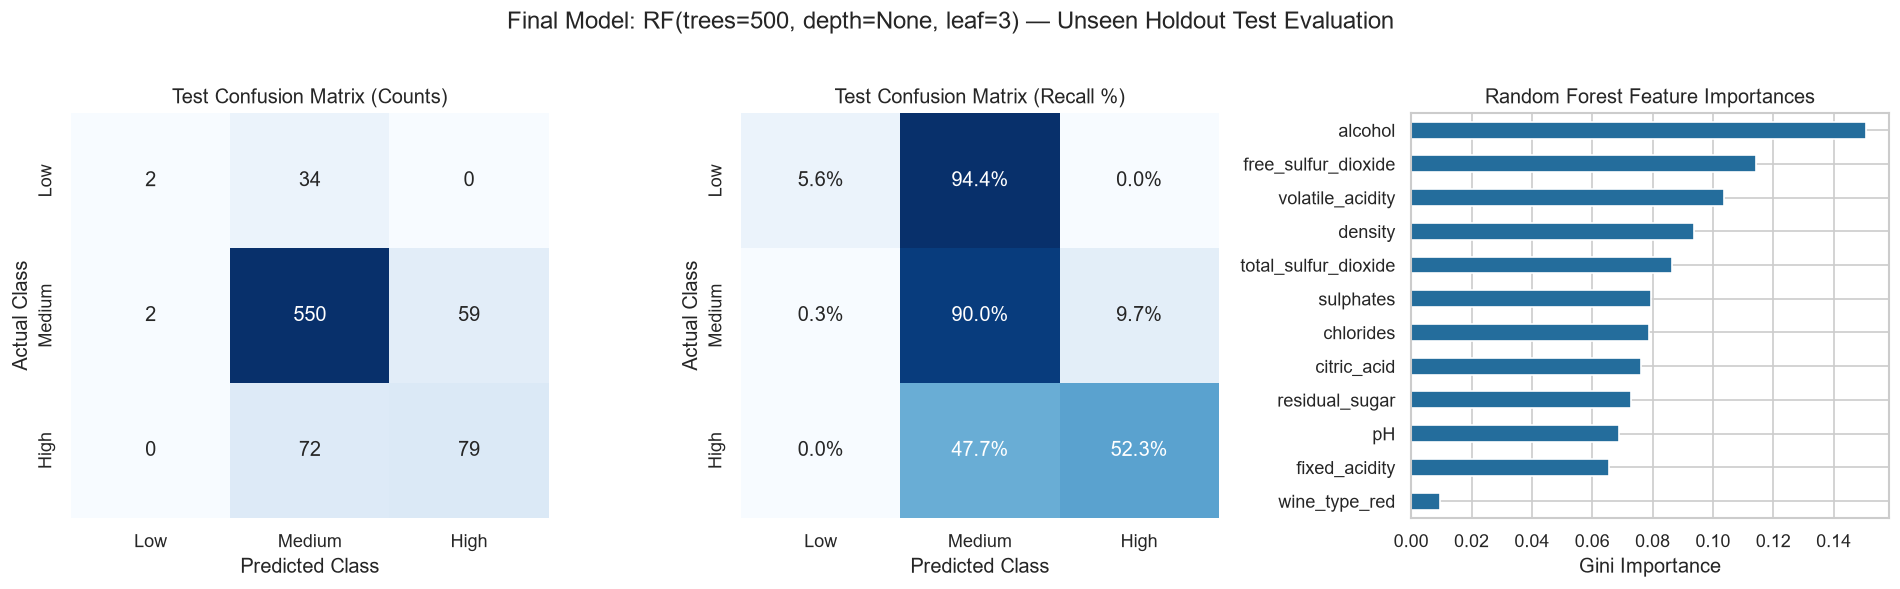

In [ ]:
#cell 7

# 1. Fit scaler and winning Random Forest on the full development set
final_scaler = StandardScaler()
X_dev_scaled = final_scaler.fit_transform(X_dev)
X_test_scaled = final_scaler.transform(X_test)

final_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=3,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1,
)
final_model.fit(X_dev_scaled, y_dev)

# 2. Predict on the locked holdout test set
col_order = [list(final_model.classes_).index(i) for i in range(len(CLASSES))]
test_proba = final_model.predict_proba(X_test_scaled)[:, col_order]
test_pred = np.argmax(test_proba, axis=1)

test_scores = evaluate_predictions(y_test, test_proba)
y_high_test = (y_test == CLASS_TO_IDX["High"]).astype(int)
p_high_test = test_proba[:, CLASS_TO_IDX["High"]]
pred_high_test = (test_pred == CLASS_TO_IDX["High"]).astype(int)

print(f"=== FINAL TEST EVALUATION: RF(trees=500, depth=None, leaf=3) (n = {len(y_test):,} unseen wines) ===")
print(f"  High-Class ROC AUC : {roc_auc_score(y_high_test, p_high_test):.4f}")
print(f"  High-Class F1      : {f1_score(y_high_test, pred_high_test, zero_division=0):.4f}")
for k, v in test_scores.items():
    print(f"  {k:19s}: {v:.4f}")

print("\nPer-Class Classification Report (Test Set):")
print(classification_report(y_test, test_pred, target_names=CLASSES, digits=4, zero_division=0))

# 3. Plot Confusion Matrices + Feature Importances
cm = confusion_matrix(y_test, test_pred, labels=range(len(CLASSES)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0], cbar=False)
axes[0].set_title("Test Confusion Matrix (Counts)")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], cbar=False)
axes[1].set_title("Test Confusion Matrix (Recall %)")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

importances = pd.Series(final_model.feature_importances_, index=FEATURES).sort_values()
importances.plot(kind="barh", ax=axes[2], color="#246d9c")
axes[2].set_title("Random Forest Feature Importances")
axes[2].set_xlabel("Gini Importance")

plt.suptitle("Final Model: RF(trees=500, depth=None, leaf=3) — Unseen Holdout Test Evaluation", y=1.02)
plt.tight_layout()
plt.show()